# Задание 4.14

Имеется две корзины с белыми и чёрными шарами. В первой корзине всего 6 шаров, при этом количество белых шаров распределено по биномиальному закону с параметрами $n=3$ и $p=0{,}8$. Во второй корзине имеется всего 11 шаров, при этом количество белых шаров распределено по биномиальному закону с параметрами $n=4$ и $p=0{,}7$. Из обеих корзин все шары перекладываются в третью корзину.

1) Какова вероятность $\mathbb P(A)$, что случайно вынутый из третьей корзины шар окажется белым (событие $A$)?
2) Найдите условную вероятность $\mathbb P(H\mid A)$ того, что случайно вынутый из третьей корзины шар первоначально находился в первой корзине (событие $H$), при условии, что он белый (событие $A$)?

**Ответ:** 1) $\mathbb P(A)=0{,}3059$; 2) $\mathbb P(H\mid A)=0{,}4615$.

*Общее требование листка:* ко всем задачам, где есть числовой ответ, напишите программу (код) с использованием инструментария **Jupyter Notebook**, который иллюстрирует график зависимости относительной частоты $\hat p(A)\overset{\text{def}}{=}\dfrac{N(A)}{N}$ события $A$ от числа проведённых реализаций опыта $N$.

## Теория

**Модель.** $X_1\sim\mathrm{Bin}(3;\,0{,}8)$ — число белых в первой корзине (из 6), $X_2\sim\mathrm{Bin}(4;\,0{,}7)$ — во второй (из 11), $X_1$ и $X_2$ независимы. В третьей корзине $17$ шаров, из них $X_1+X_2$ белых.

**1) Полная вероятность.** Гипотезы — значения пары $(X_1,X_2)$:

$$
\mathbb P(A)=\sum_{i,j}\mathbb P(X_1=i)\,\mathbb P(X_2=j)\,\frac{i+j}{17}=\frac{\mathbb E X_1+\mathbb E X_2}{17}=\frac{3\cdot0{,}8+4\cdot0{,}7}{17}=\frac{5{,}2}{17}=\frac{26}{85}\approx0{,}3059 .
$$

**2) Формула Байеса.** Шар белый и из первой корзины, если вынут один из $X_1$ белых шаров первой корзины:

$$
\mathbb P(HA)=\frac{\mathbb E X_1}{17}=\frac{2{,}4}{17},\qquad
\mathbb P(H\mid A)=\frac{\mathbb P(HA)}{\mathbb P(A)}=\frac{2{,}4}{5{,}2}=\frac{6}{13}\approx0{,}4615 .
$$

Для сравнения: без условия $\mathbb P(H)=\frac{6}{17}\approx0{,}353$. Знание, что шар белый, повышает шанс первой корзины, потому что доля белых в ней больше ($2{,}4/6=0{,}4$ против $2{,}8/11\approx0{,}255$).

**Моделирование.** В каждом опыте генерируем составы корзин, перемешиваем всё в третьей корзине и вынимаем шар. Условная частота $\hat p(H\mid A)=N(HA)/N(A)$.

1) P(A)   = 26/85 = 0.3059
2) P(H|A) = 6/13 = 0.4615


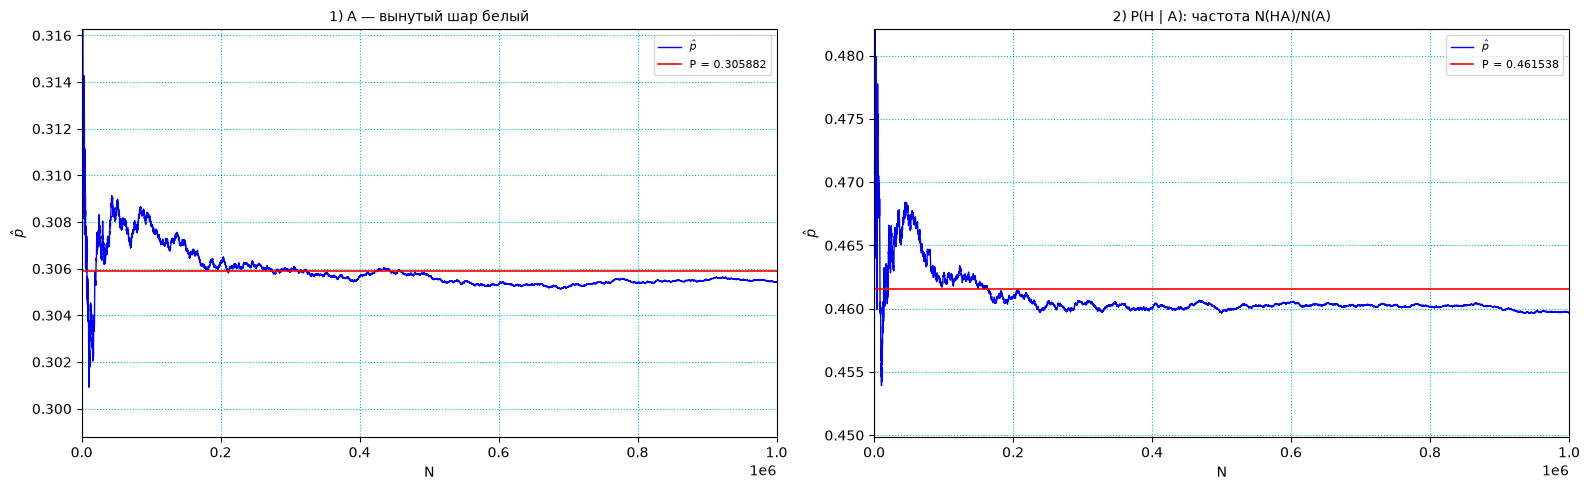

Моделирование (N = 1000000): p̂(A) = 0.3054,  p̂(H|A) = 0.4597


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
from math import comb

rng = np.random.default_rng(2026)

def plot_freq(ax, hits, p, title, cond=None, skip=None):
    """График относительной частоты p̂ = N(A)/N от числа опытов N (красная линия — точная вероятность p).
    Если задано cond — строится условная частота N(A∩B)/N(B)."""
    hits = np.asarray(hits, dtype=bool)
    n = np.arange(1, hits.size + 1)
    if cond is None:
        freq = np.cumsum(hits) / n                                   # p̂(A) после каждого опыта
    else:
        nb = np.cumsum(cond)
        freq = np.where(nb > 0, np.cumsum(hits & cond) / np.maximum(nb, 1), np.nan)  # p̂(A|B)
    step = max(1, hits.size // 20000)                                # прореживаем точки для отрисовки
    ax.plot(n[::step], freq[::step], color="blue", lw=1, label=r"$\hat p$")
    ax.axhline(p, color="red", lw=1.2, label=f"P = {p:.6f}")
    skip = skip or max(50, hits.size // 300)                         # первые опыты — сильный разброс
    lo, hi = np.nanmin(freq[skip:]), np.nanmax(freq[skip:])
    lo, hi = min(lo, p), max(hi, p)
    pad = 0.15 * (hi - lo) + 1e-12
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, hits.size)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("N")
    ax.set_ylabel(r"$\hat p$")
    ax.grid(ls=":", color="c")
    ax.legend(fontsize=8, loc="upper right")
    return freq[-1]


# ---------- Точные значения: полная вероятность и формула Байеса ----------
def binom_pmf(n, p):
    return {k: comb(n, k) * p**k * (1 - p)**(n - k) for k in range(n + 1)}

b1, b2 = binom_pmf(3, Fraction(8, 10)), binom_pmf(4, Fraction(7, 10))
PA = sum(b1[i]*b2[j]*Fraction(i + j, 17) for i in b1 for j in b2)    # P(A)
PHA = sum(b1[i]*b2[j]*Fraction(i, 17) for i in b1 for j in b2)       # P(H·A)
PH_A = PHA / PA                                                      # Байес
print(f"1) P(A)   = {PA} = {float(PA):.4f}")
print(f"2) P(H|A) = {PH_A} = {float(PH_A):.4f}")

# ---------- Моделирование ----------
N = 1_000_000
X1 = rng.binomial(3, 0.8, N)                 # белых в 1-й корзине (из 6)
X2 = rng.binomial(4, 0.7, N)                 # белых во 2-й корзине (из 11)
ball = rng.integers(0, 17, N)                # номер вынутого шара: 0..5 — из 1-й корзины, 6..16 — из 2-й
H = ball < 6                                 # шар из первой корзины
A = np.where(H, ball < X1, ball - 6 < X2)    # шар белый (в каждой корзине белые — первые по номеру)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
pa = plot_freq(axes[0], A, float(PA), "1) A — вынутый шар белый")
ph = plot_freq(axes[1], H, float(PH_A), "2) P(H | A): частота N(HA)/N(A)", cond=A)
fig.tight_layout()
plt.show()

print(f"Моделирование (N = {N}): p̂(A) = {pa:.4f},  p̂(H|A) = {ph:.4f}")